DAY 14: CONVECTION PATTERN ANALYSIS
Reading results from: C:\Users\athil\OneDrive\Desktop\combined_mantle_results_2
Number of usable simulations: 4
Loaded Ra = 500.0
Loaded Ra = 1000.0
Loaded Ra = 2500.0
Loaded Ra = 5000.0


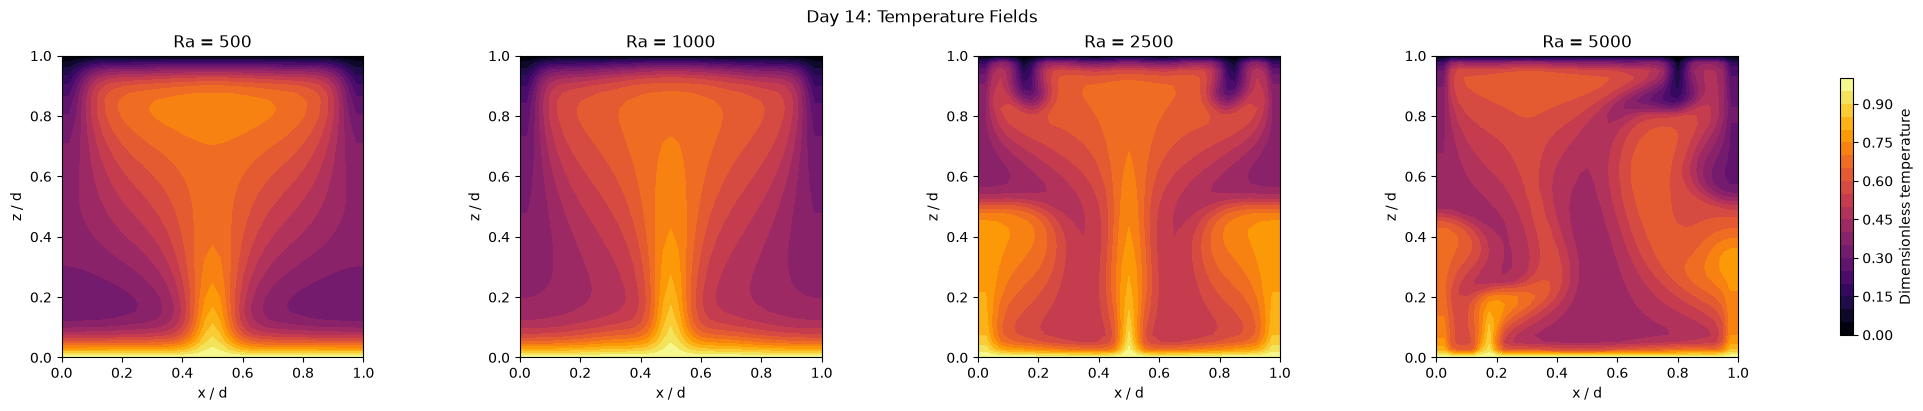

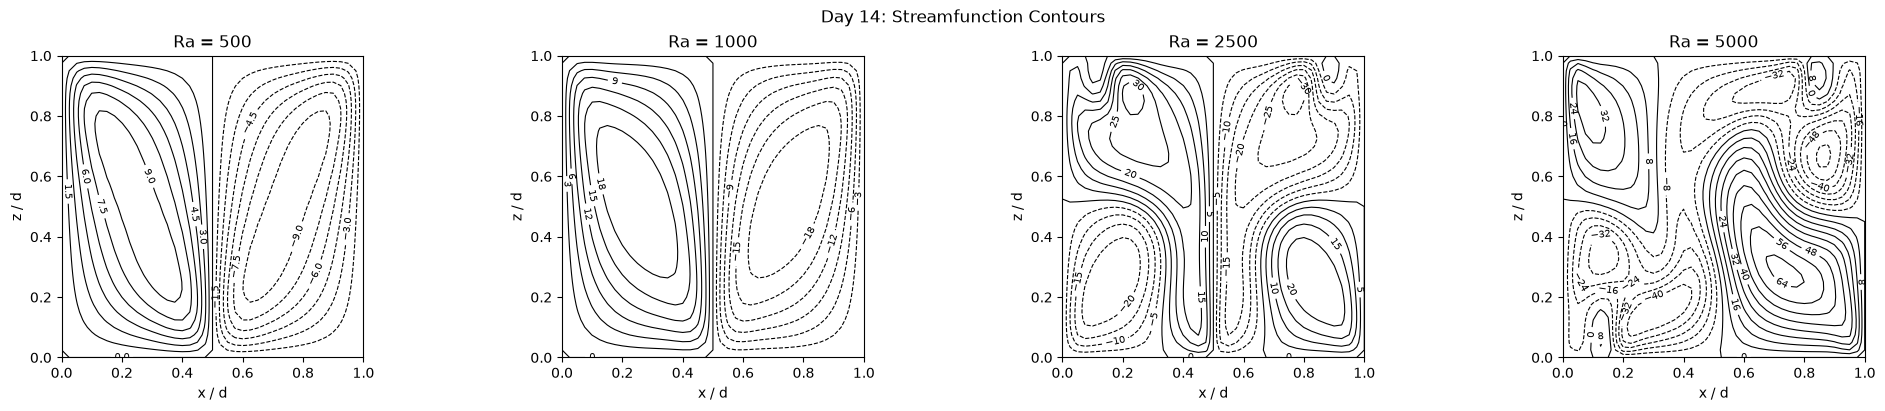

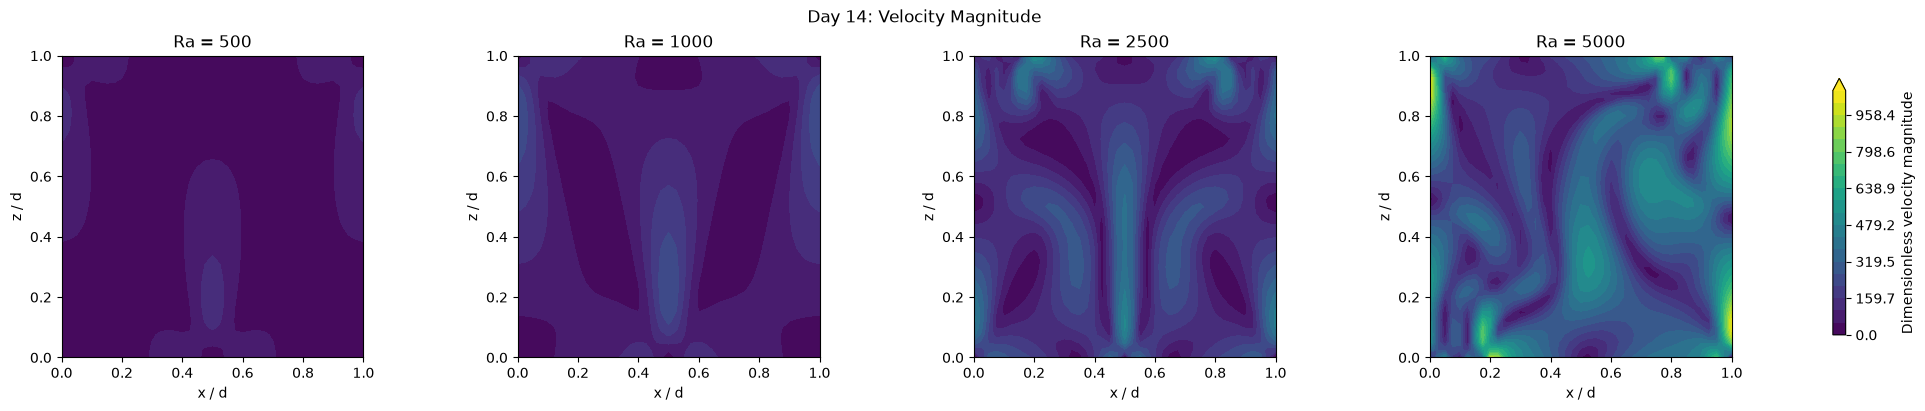

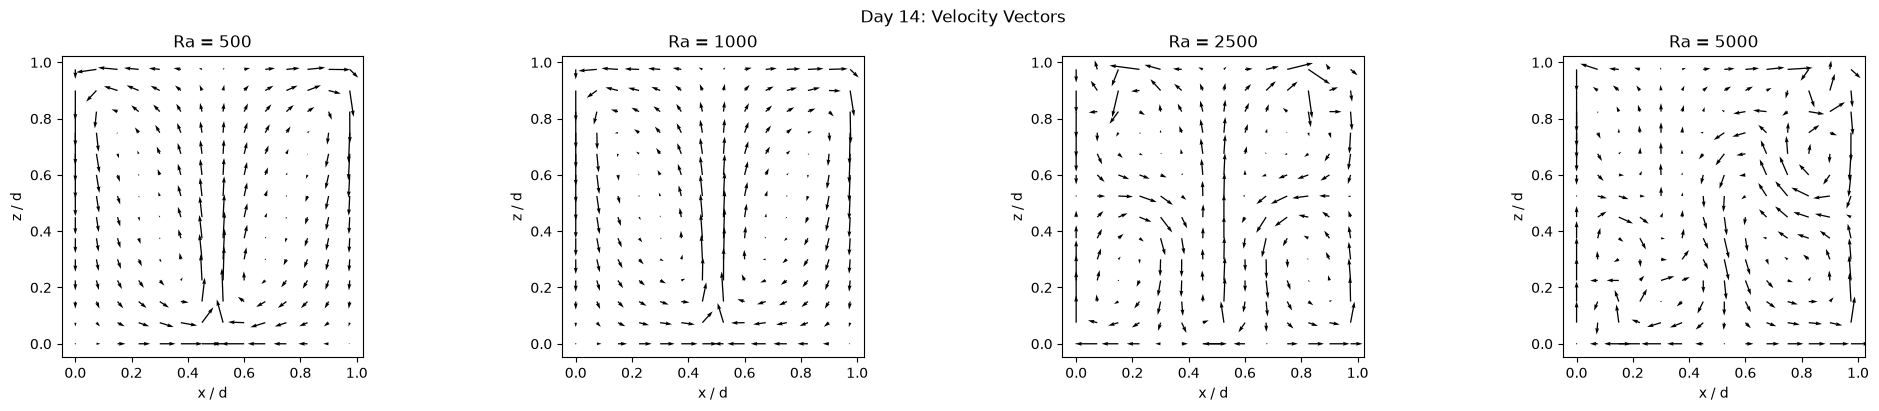


Summary saved: day14_convection_patterns\day14_pattern_summary.csv


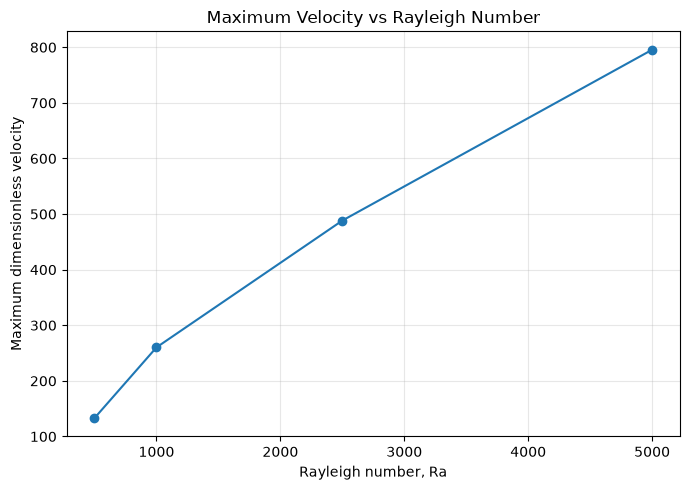


DAY 14 COMPLETED
Results folder: C:\Users\athil\OneDrive\Desktop\day14_convection_patterns
Generated files:
1. day14_temperature_comparison.png
2. day14_streamfunction_comparison.png
3. day14_velocity_magnitude.png
4. day14_velocity_vectors.png
5. day14_pattern_summary.csv
6. day14_max_velocity_vs_Ra.png

Use these plots to compare the simulated flow patterns.
Visual differences alone do not establish physical validity.


In [1]:
"""
DAY 14: VISUALISATION OF MANTLE CONVECTION PATTERNS

Objectives:
1. Compare temperature fields for different Rayleigh numbers.
2. Visualise streamfunction contours and circulation cells.
3. Compare velocity magnitude and velocity vectors.
4. Save figures and a CSV summary.

Required libraries:
pip install numpy matplotlib
"""

from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. SETTINGS
# ============================================================

OUTPUT_DIR = Path("day14_convection_patterns")
OUTPUT_DIR.mkdir(exist_ok=True)

print("DAY 14: CONVECTION PATTERN ANALYSIS")


# ============================================================
# 2. FIND SAVED SIMULATION FILES
# ============================================================

possible_folders = []

for folder in Path(".").glob("combined_mantle_results*"):

    files = list(folder.glob("mantle_Ra_*.npz"))

    if files:
        possible_folders.append((folder, files))

if not possible_folders:
    raise FileNotFoundError(
        "No mantle_Ra_*.npz files were found.\n"
        "Run the combined mantle convection program first."
    )

# Use the most recently modified results folder.
results_folder, simulation_files = max(
    possible_folders,
    key=lambda item: item[0].stat().st_mtime
)

print("Reading results from:", results_folder.resolve())


# ============================================================
# 3. LOAD SIMULATION DATA
# ============================================================

results = []

for file in simulation_files:

    with np.load(file) as data:

        required = ["ra", "x", "z", "T", "psi", "u", "w", "speed"]

        missing = [key for key in required if key not in data]

        if missing:
            print("Skipping", file.name, "- missing:", missing)
            continue

        result = {
            "Ra": float(data["ra"]),
            "x": data["x"].copy(),
            "z": data["z"].copy(),
            "T": data["T"].copy(),
            "psi": data["psi"].copy(),
            "u": data["u"].copy(),
            "w": data["w"].copy(),
            "speed": data["speed"].copy(),
            "file": file.name
        }

        if not all(
            np.isfinite(result[key]).all()
            for key in ["T", "psi", "u", "w", "speed"]
        ):
            print("Skipping non-finite data:", file.name)
            continue

        results.append(result)

results.sort(key=lambda item: item["Ra"])

if not results:
    raise ValueError("No usable simulation files were found.")

print("Number of usable simulations:", len(results))

for result in results:
    print("Loaded Ra =", result["Ra"])


# ============================================================
# 4. CREATE GRID COORDINATES
# ============================================================

for result in results:

    X, Z = np.meshgrid(result["x"], result["z"])

    result["X"] = X
    result["Z"] = Z


# ============================================================
# 5. TEMPERATURE FIELD COMPARISON
# ============================================================

fig, axes = plt.subplots(
    1,
    len(results),
    figsize=(5 * len(results), 4),
    squeeze=False,
    constrained_layout=True
)

last_contour = None

for ax, result in zip(axes[0], results):

    last_contour = ax.contourf(
        result["X"],
        result["Z"],
        result["T"],
        levels=21,
        cmap="inferno"
    )

    ax.set_title(f"Ra = {result['Ra']:g}")
    ax.set_xlabel("x / d")
    ax.set_ylabel("z / d")
    ax.set_aspect("equal")

fig.colorbar(
    last_contour,
    ax=axes.ravel().tolist(),
    label="Dimensionless temperature",
    shrink=0.85
)

fig.suptitle("Day 14: Temperature Fields")

fig.savefig(
    OUTPUT_DIR / "day14_temperature_comparison.png",
    dpi=180
)

plt.show()


# ============================================================
# 6. STREAMFUNCTION CONTOURS
# ============================================================

fig, axes = plt.subplots(
    1,
    len(results),
    figsize=(5 * len(results), 4),
    squeeze=False,
    constrained_layout=True
)

for ax, result in zip(axes[0], results):

    contour = ax.contour(
        result["X"],
        result["Z"],
        result["psi"],
        levels=15,
        colors="black",
        linewidths=0.8
    )

    ax.clabel(contour, inline=True, fontsize=7)

    ax.set_title(f"Ra = {result['Ra']:g}")
    ax.set_xlabel("x / d")
    ax.set_ylabel("z / d")
    ax.set_aspect("equal")

fig.suptitle("Day 14: Streamfunction Contours")

fig.savefig(
    OUTPUT_DIR / "day14_streamfunction_comparison.png",
    dpi=180
)

plt.show()


# ============================================================
# 7. VELOCITY MAGNITUDE COMPARISON
# ============================================================

fig, axes = plt.subplots(
    1,
    len(results),
    figsize=(5 * len(results), 4),
    squeeze=False,
    constrained_layout=True
)

maximum_speed = max(
    np.max(result["speed"]) for result in results
)

levels = np.linspace(
    0,
    max(maximum_speed, 1e-12),
    21
)

last_contour = None

for ax, result in zip(axes[0], results):

    last_contour = ax.contourf(
        result["X"],
        result["Z"],
        result["speed"],
        levels=levels,
        cmap="viridis",
        extend="max"
    )

    ax.set_title(f"Ra = {result['Ra']:g}")
    ax.set_xlabel("x / d")
    ax.set_ylabel("z / d")
    ax.set_aspect("equal")

fig.colorbar(
    last_contour,
    ax=axes.ravel().tolist(),
    label="Dimensionless velocity magnitude",
    shrink=0.85
)

fig.suptitle("Day 14: Velocity Magnitude")

fig.savefig(
    OUTPUT_DIR / "day14_velocity_magnitude.png",
    dpi=180
)

plt.show()


# ============================================================
# 8. VELOCITY VECTOR PLOTS
# ============================================================

fig, axes = plt.subplots(
    1,
    len(results),
    figsize=(5 * len(results), 4),
    squeeze=False,
    constrained_layout=True
)

for ax, result in zip(axes[0], results):

    # Plot every third grid point to keep the arrows readable.
    X = result["X"][::3, ::3]
    Z = result["Z"][::3, ::3]

    u = result["u"][::3, ::3]
    w = result["w"][::3, ::3]

    ax.quiver(
        X, Z, u, w,
        angles="xy",
        scale_units="xy",
        scale=None
    )

    ax.set_title(f"Ra = {result['Ra']:g}")
    ax.set_xlabel("x / d")
    ax.set_ylabel("z / d")
    ax.set_aspect("equal")

fig.suptitle("Day 14: Velocity Vectors")

fig.savefig(
    OUTPUT_DIR / "day14_velocity_vectors.png",
    dpi=180
)

plt.show()


# ============================================================
# 9. CREATE A NUMERICAL COMPARISON TABLE
# ============================================================

summary = []

for result in results:

    T = result["T"]
    speed = result["speed"]
    psi = result["psi"]

    summary.append({
        "Ra": result["Ra"],
        "temperature_min": float(np.min(T)),
        "temperature_max": float(np.max(T)),
        "maximum_velocity": float(
            np.max(speed[1:-1, 1:-1])
        ),
        "mean_velocity_magnitude": float(
            np.mean(speed[1:-1, 1:-1])
        ),
        "maximum_absolute_streamfunction": float(
            np.max(np.abs(psi))
        ),
        "temperature_finite": bool(np.isfinite(T).all()),
        "velocity_finite": bool(np.isfinite(speed).all())
    })


# ============================================================
# 10. SAVE CSV SUMMARY
# ============================================================

csv_file = OUTPUT_DIR / "day14_pattern_summary.csv"

with open(
    csv_file,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(summary[0].keys())
    )

    writer.writeheader()
    writer.writerows(summary)

print("\nSummary saved:", csv_file)


# ============================================================
# 11. MAXIMUM VELOCITY VS RAYLEIGH NUMBER
# ============================================================

ra_values = [row["Ra"] for row in summary]

max_velocities = [
    row["maximum_velocity"] for row in summary
]

plt.figure(figsize=(7, 5))

plt.plot(
    ra_values,
    max_velocities,
    "o-"
)

plt.xlabel("Rayleigh number, Ra")
plt.ylabel("Maximum dimensionless velocity")
plt.title("Maximum Velocity vs Rayleigh Number")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day14_max_velocity_vs_Ra.png",
    dpi=180
)

plt.show()


# ============================================================
# 12. FINISH
# ============================================================

print("\n" + "=" * 55)
print("DAY 14 COMPLETED")
print("=" * 55)

print("Results folder:", OUTPUT_DIR.resolve())

print("Generated files:")
print("1. day14_temperature_comparison.png")
print("2. day14_streamfunction_comparison.png")
print("3. day14_velocity_magnitude.png")
print("4. day14_velocity_vectors.png")
print("5. day14_pattern_summary.csv")
print("6. day14_max_velocity_vs_Ra.png")

print("\nUse these plots to compare the simulated flow patterns.")
print("Visual differences alone do not establish physical validity.")